# Fase 1: Análisis Exploratorio de Datos (EDA) - AI Security Guard

## Objetivos de esta fase:
1. Cargar y verificar la integridad del dataset principal (`dataset_malwares.csv`).
2. Conocer la volumetría, tipos de datos y presencia de valores nulos o duplicados.
3. Analizar la distribución de la variable objetivo (`Malware`).
4. Identificar posibles sesgos, variables constantes o fugas de información (*data leakage*).

## 1 Cargar y verificar la integridad del dataset principal

Esta celda utiliza comandos de terminal (mediante el signo *!*) para clonar el repositorio remoto de GitHub en la máquina virtual temporal de Colab y cambia la ruta activa de trabajo (*os.chdir*) para que Python reconozca toda la estructura de carpetas (*data/, src/, etc.*).

In [4]:
# 1. Clonar el repositorio oficial desde GitHub
!git clone https://github.com/EliasHernandezBar/mini-antivirus-ai

# 2. Cambiar el directorio actual de Colab a la carpeta recién clonada
import os
os.chdir('mini-antivirus-ai')

print("¡Repositorio clonado con éxito y directorio de trabajo actualizado!")

Cloning into 'mini-antivirus-ai'...
remote: Enumerating objects: 17, done.
remote: Counting objects: 100% (17/17), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 17 (delta 3), reused 16 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (17/17), 1.56 MiB | 8.01 MiB/s, done.
Resolving deltas: 100% (3/3), done.
¡Repositorio clonado con éxito y directorio de trabajo actualizado!


Importamos las librerías estándar del ecosistema de ciencia de datos en Python para manipulación tabular, cálculos numéricos y visualización gráfica.

In [5]:
# Importación de librerías clave para el análisis de datos
import pandas as pd  # Manejo y estructuración de dataframes
import numpy as np   # Operaciones numéricas eficientes
import matplotlib.pyplot as plt  # Creación de gráficos personalizados
import seaborn as sns            # Visualización estadística avanzada

# Configuración del estilo visual para los gráficos
sns.set_theme(style="whitegrid")
print("Librerías importadas correctamente y entorno configurado.")

Librerías importadas correctamente y entorno configurado.


Leemos el archivo CSV directamente desde la ruta local del repositorio clonado (*data/dataset_malwares.csv*) y comprobamos sus dimensiones iniciales con el atributo *.shape* para confirmar que se han cargado las 19.611 filas y 78 columnas esperadas.

In [7]:
# 3. Cargar el dataset principal utilizando la ruta relativa dentro del proyecto
df = pd.read_csv('data/dataset_malwares.csv')

# Comprobar las dimensiones del DataFrame cargado
print(f"Dataset cargado correctamente.")
print(f"Número de filas (registros): {df.shape[0]}")
print(f"Número de columnas (variables): {df.shape[1]}")

Dataset cargado correctamente.
Número de filas (registros): 19611
Número de columnas (variables): 79


## 2 Conocer la volumetría, tipos de datos y presencia de valores nulos o duplicados.

Inspección visual preliminar con *.head() / .sample()* y revisión de tipos de datos y uso de memoria con *.info()*.

In [10]:
# Visualizar las primeras 5 filas para entender la estructura de las columnas
display(df.head())

# Inspección general de tipos de datos, valores no nulos y uso de memoria
print("\n--- INFORMACIÓN GENERAL DEL DATAFRAME ---")
print("")
df.info()

,Name,e_magic,e_cblp,e_cp,e_crlc,e_cparhdr,e_minalloc,e_maxalloc,e_ss,e_sp,...,SectionMaxChar,SectionMainChar,DirectoryEntryImport,DirectoryEntryImportSize,DirectoryEntryExport,ImageDirectoryEntryExport,ImageDirectoryEntryImport,ImageDirectoryEntryResource,ImageDirectoryEntryException,ImageDirectoryEntrySecurity
0,VirusShare_a878ba26000edaac5c98eff4432723b3,23117,144,3,0,4,0,65535,0,184,...,3758096608,0,7,152,0,0,54440,77824,73728,0
1,VirusShare_ef9130570fddc174b312b2047f5f4cf0,23117,144,3,0,4,0,65535,0,184,...,3791650880,0,16,311,0,0,262276,294912,0,346112
2,VirusShare_ef84cdeba22be72a69b198213dada81a,23117,144,3,0,4,0,65535,0,184,...,3221225536,0,6,176,0,0,36864,40960,0,0
3,VirusShare_6bf3608e60ebc16cbcff6ed5467d469e,23117,144,3,0,4,0,65535,0,184,...,3224371328,0,8,155,0,0,356352,1003520,0,14109472
4,VirusShare_2cc94d952b2efb13c7d6bbe0dd59d3fb,23117,144,3,0,4,0,65535,0,184,...,3227516992,0,2,43,0,0,61440,73728,0,90624



--- INFORMACIÓN GENERAL DEL DATAFRAME ---

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19611 entries, 0 to 19610
Data columns (total 79 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Name                          19611 non-null  object 
 1   e_magic                       19611 non-null  int64  
 2   e_cblp                        19611 non-null  int64  
 3   e_cp                          19611 non-null  int64  
 4   e_crlc                        19611 non-null  int64  
 5   e_cparhdr                     19611 non-null  int64  
 6   e_minalloc                    19611 non-null  int64  
 7   e_maxalloc                    19611 non-null  int64  
 8   e_ss                          19611 non-null  int64  
 9   e_sp                          19611 non-null  int64  
 10  e_csum                        19611 non-null  int64  
 11  e_ip                          19611 non-null  int64  
 12  e_cs            

En esta fase de auditoría de calidad comprobamos si el dataset tiene valores perdidos (*isnull* ), registros repetidos exactamente (*duplicated*) o variables que no aportan información porque tienen el mismo valor en todas las filas (columnas constantes).

In [13]:
# 1. Comprobar valores nulos en todo el DataFrame
nulos_totales = df.isnull().sum().sum()
print(f"Número total de valores nulos en el dataset: {nulos_totales}")

# 2. Comprobar filas duplicadas exactas
filas_duplicadas = df.duplicated().sum()
print(f"Número de filas duplicadas exactas: {filas_duplicadas}")

# 3. Identificar columnas constantes (aquellas con un único valor único para todos los registros)
columnas_constantes = [col for col in df.columns if df[col].nunique() <= 1]
print(f"Columnas constantes detectadas: {columnas_constantes}")
print(f"Cantidad de columnas constantes: len(columnas_constantes)")

Número total de valores nulos en el dataset: 0
Número de filas duplicadas exactas: 0
Columnas constantes detectadas: ['e_magic', 'SectionMaxEntropy', 'SectionMaxRawsize', 'SectionMaxVirtualsize', 'SectionMinPhysical', 'SectionMinVirtual', 'SectionMinPointerData', 'SectionMainChar']
Cantidad de columnas constantes: len(columnas_constantes)


Utilizamos el método *.unique()* o *.value_counts()* para identificar los valores únicos que toma la etiqueta que queremos predecir (*Malware*), comprobando si es un problema de clasificación binaria (0 y 1).

In [11]:
# Comprobar los valores únicos presentes en la variable objetivo ('Malware')
print("Valores únicos en la variable objetivo ('Malware'):")
print(df['Malware'].unique())

# Recuento absoluto de registros por cada clase
print("\nRecuento absoluto por clase:")
print(df['Malware'].value_counts())

Valores únicos en la variable objetivo ('Malware'):
[1 0]

Recuento absoluto por clase:
Malware
1    14599
0     5012
Name: count, dtype: int64


Utilizamos el método *.describe()* para obtener un resumen estadístico de las variables numéricas (media, desviación estándar, mínimos, cuartiles y máximos). Esto nos permite detectar de un vistazo si hay asimetrías severas o rangos de valores muy dispares entre columnas.

In [17]:
# Obtener un resumen estadístico de las variables numéricas del dataset
print("Resumen estadístico de las características numéricas:")
display(df.describe().T[['count', 'mean', 'std', 'min', 'max']])

Resumen estadístico de las características numéricas:


,count,mean,std,min,max
e_magic,19611.0,2.311700e+04,0.000000e+00,23117.0,2.311700e+04
e_cblp,19611.0,1.786157e+02,9.872007e+02,0.0,5.944800e+04
e_cp,19611.0,7.166075e+01,1.445193e+03,0.0,6.320000e+04
e_crlc,19611.0,4.914696e+01,1.212202e+03,0.0,6.461300e+04
e_cparhdr,19611.0,3.737071e+01,8.645154e+02,0.0,4.369000e+04
...,...,...,...,...,...
ImageDirectoryEntryExport,19611.0,3.368566e+05,2.181191e+07,0.0,2.147484e+09
ImageDirectoryEntryImport,19611.0,4.047213e+05,4.704601e+06,0.0,5.368914e+08
ImageDirectoryEntryResource,19611.0,5.555810e+05,6.772167e+06,0.0,8.304108e+08
ImageDirectoryEntryException,19611.0,1.238834e+06,5.868961e+07,0.0,2.906159e+09


## 3 Analizar la distribución de la variable objetivo (Malware)

En Machine Learning, calcular los porcentajes de cada clase mediante *normalize=True* es fundamental para detectar desequilibrios (class imbalance). Esto nos dirá si necesitamos métricas adicionales más allá del accuracy en futuras fases (como Precision, Recall o F1-score).

Distribución porcentual de la variable objetivo:
- Malware (Clase 1): 74.44%
- Benigno (Clase 0): 25.56%


/tmp/ipykernel_626/3607784989.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Malware', palette='Set2')


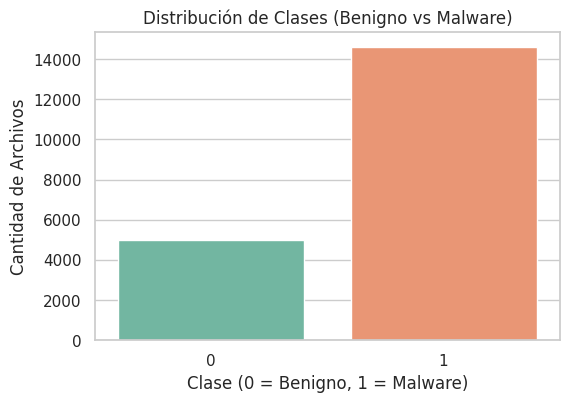

In [12]:
# Calcular la distribución porcentual de la variable objetivo
distribucion_pct = df['Malware'].value_counts(normalize=True) * 100

print("Distribución porcentual de la variable objetivo:")
for clase, porcentaje in distribucion_pct.items():
    estado = "Benigno (Clase 0)" if clase == 0 else "Malware (Clase 1)"
    print(f"- {estado}: {porcentaje:.2f}%")

# Pequeña visualización rápida con Seaborn para ilustrar el desequilibrio
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Malware', palette='Set2')
plt.title('Distribución de Clases (Benigno vs Malware)')
plt.xlabel('Clase (0 = Benigno, 1 = Malware)')
plt.ylabel('Cantidad de Archivos')
plt.show()

## 4 Identificar posibles sesgos, variables constantes y fugas de información (data leakage)




Analizamos la cardinalidad (número de valores únicos) de la columna *Name*. Como veremos, cada fila tiene un nombre único, lo que significa que funciona como un identificador y no como una característica matemática apta para entrenar un modelo de Machine Learning de forma directa.

In [14]:
# Analizar la cardinalidad y unicidad de la columna 'Name'
if 'Name' in df.columns:
    total_registros = len(df)
    nombres_unicos = df['Name'].nunique()

    print(f"Total de registros en el dataset: {total_registros}")
    print(f"Valores únicos en la columna 'Name': {nombres_unicos}")

    if total_registros == nombres_unicos:
        print("\n[Conclusión]: La columna 'Name' tiene cardinalidad máxima (cada nombre es único). "
              "Debe ser excluida de los modelos de Machine Learning para evitar memorización o fugas de datos.")
else:
    print("La columna 'Name' no se encuentra en el DataFrame.")

Total de registros en el dataset: 19611
Valores únicos en la columna 'Name': 19611

[Conclusión]: La columna 'Name' tiene cardinalidad máxima (cada nombre es único). Debe ser excluida de los modelos de Machine Learning para evitar memorización o fugas de datos.


En proyectos de ciberseguridad defensiva con características PE, ciertas variables estructurales (como las versiones del enlazador o del sistema operativo) suelen mostrar patrones interesantes al compararlas mediante la media o la mediana agrupadas por la variable objetivo (*Malware*).

In [18]:
# Seleccionar algunas variables estructurales representativas mencionadas en el análisis del proyecto
variables_muestra = ['MajorLinkerVersion', 'SizeOfCode', 'ImageBase', 'MajorOperatingSystemVersion']

# Calcular la media de estas variables agrupadas por la clase (0 = Benigno, 1 = Malware)
print("Media de variables estructurales según la clase (Benigno vs Malware):")
display(df.groupby('Malware')[variables_muestra].mean())

Media de variables estructurales según la clase (Benigno vs Malware):


,MajorLinkerVersion,SizeOfCode,ImageBase,MajorOperatingSystemVersion
Malware,,,,
0,10.973663,2.770676e+05,1.153568e+11,5.630487
1,8.003493,1.951918e+06,2.132334e+09,29.614768


En proyectos de Machine Learning e ingestión de datos, es vital comprobar si existen patrones en las cadenas de texto (como prefijos en los nombres de los archivos) que estén perfectamente alineados con las clases a predecir. Esto nos ayuda a detectar indicios de *data leakage* (fuga de información) o sesgos procedimentales antes de entrenar ningún modelo.

In [19]:
# Verificar si los nombres de los archivos contienen el prefijo 'VirusShare_'
if 'Name' in df.columns:
    # Crear una variable booleana temporal para identificar el prefijo
    df['Has_VirusShare_Prefix'] = df['Name'].astype(str).str.startswith('VirusShare_')

    # Realizar una tabla de contingencia cruzando esta condición con la variable objetivo 'Malware'
    cruce_prefijo = pd.crosstab(df['Has_VirusShare_Prefix'], df['Malware'], margins=True)

    print("Tabla de contingencia (Prefijo 'VirusShare_' vs. Malware):")
    display(cruce_prefijo)

    # Limpiar la columna temporal para no alterar el DataFrame base
    df.drop(columns=['Has_VirusShare_Prefix'], inplace=True)
else:
    print("La columna 'Name' no está disponible en el DataFrame.")

Tabla de contingencia (Prefijo 'VirusShare_' vs. Malware):


Malware,0,1,All
Has_VirusShare_Prefix,,,
False,5012,0,5012
True,0,14599,14599
All,5012,14599,19611


## Conclusiones y Próximos Pasos

### Resumen de hallazgos del EDA:

* **Volumetría y calidad técnica:** El dataset principal cuenta con 19.611 registros y 79 columnas, sin presencia de valores nulos ni filas duplicadas exactas.
* **Distribución de la variable objetivo (`Malware`):** Se observa un desequilibrio de clases, donde el 25,6% (5.012 registros) corresponde a archivos benignos y el 74,4% (14.599 registros) a muestras de malware[cite: 1].
* **Auditoría de identificadores y columnas constantes:** Se identificaron ocho columnas constantes y se confirmó que la columna `Name` posee una cardinalidad del 100% (19.611 valores únicos), por lo que debe ser excluida de los modelos de Machine Learning para evitar sesgos de memorización[cite: 1].
* **Hallazgo crítico (Indicios de fuga de información / Procedencia):** Se detectó que el 100% de los registros de malware comienzan con el prefijo `VirusShare_`, un patrón ausente en los archivos benignos[cite: 1]. Esto demuestra que los datos provienen de fuentes o repositorios de origen distintos, advirtiéndonos sobre la necesidad de auditar variables estructurales (como versiones del *linker* o marcas de tiempo) que puedan filtrar esta procedencia en lugar de generalizar patrones reales de ciberseguridad[cite: 1].

### Decisiones pendientes para la Fase 2 (Data Cleaning):

1. Proceder a la eliminación justificada de las ocho columnas constantes detectadas.
2. Aislar y excluir la columna `Name` de las matrices de entrenamiento.
3. Evaluar el impacto de las variables temporales y de versiones antes de pasar a la fase de entrenamiento y comparación de modelos.